# Course Enrolment and Pass Rate Analysis — Exploratory Data Analysis (EDA)

**Student:** Rashmi Singh (B.Tech 2nd Year)  
**Institution:** ABES Engineering College  
**Domain:** Education and Academic Analytics  
**Passing Rule:** `marks >= 40` out of `100` (`Pass`), `marks < 40` (`Fail`), unavailable/invalid marks (`Missing/Invalid`)

This notebook explores the cleaned academic datasets to answer five core business questions:
1. Which courses have the highest student enrolment?
2. Which courses have the highest and lowest pass rates?
3. What is the overall student pass percentage?
4. How does student performance vary across semesters?
5. Which courses require academic improvement based on their failure rates?

## 1. Import Libraries & Reuse Project Rules

The cell below imports `pandas`, `numpy`, and `matplotlib`, resolves the repository root using relative paths (`Path.cwd()`), and imports the verified KPI functions directly from `python/analysis.py`. Because `python/analysis.py` is protected by an `if __name__ == "__main__":` guard, importing its functions does not execute the script or overwrite any report files.

In [1]:
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Resolve repository root using relative paths (works from repo root or notebooks/)
cwd = Path.cwd()
PROJECT_ROOT = cwd if (cwd / "data" / "clean").exists() else cwd.parent
PYTHON_DIR = PROJECT_ROOT / "python"
DATA_CLEAN_DIR = PROJECT_ROOT / "data" / "clean"
REPORTS_DIR = PROJECT_ROOT / "reports"

if str(PYTHON_DIR) not in sys.path:
    sys.path.insert(0, str(PYTHON_DIR))

from analysis import (
    CHART_PALETTE,
    PASSING_MARKS,
    build_merged_dataframe,
    calculate_kpis,
    load_clean_data,
)

# Restore Jupyter inline backend after importing analysis.py (which uses Agg for CLI PNG saving)
%matplotlib inline

print("Project Root:", PROJECT_ROOT)
print("Passing Threshold:", PASSING_MARKS, "marks out of 100")

Project Root: C:\Users\RASHMI\OneDrive\Desktop\course analysis project\Course-Enrolment-and-Pass-Rate-Analysis
Passing Threshold: 40 marks out of 100


## 2. Load Cleaned Datasets

Here we load the three cleaned CSV files (`students.csv`, `courses.csv`, `enrolments.csv`) read-only from `data/clean/` and join them into a single analytical table (`merged_df`) using `student_id` and `course_id`.

In [2]:
students_df, courses_df, enrolments_df = load_clean_data(DATA_CLEAN_DIR)
merged_df = build_merged_dataframe(students_df, courses_df, enrolments_df)

print(f"students_df shape   : {students_df.shape}")
print(f"courses_df shape    : {courses_df.shape}")
print(f"enrolments_df shape : {enrolments_df.shape}")
print(f"merged_df shape     : {merged_df.shape}")

display(students_df.head(3))
display(courses_df.head(3))
display(merged_df.head(5))

students_df shape   : (250, 5)
courses_df shape    : (10, 4)
enrolments_df shape : (1337, 9)
merged_df shape     : (1337, 16)


,student_id,student_name,gender,department,admission_year
0,STU0001,Pallavi Malhotra,Female,ME,2024
1,STU0002,Mohit Yadav,Male,ME,2024
2,STU0003,Shivam Malhotra,Male,IT,2024


,course_id,course_name,course_category,credits
0,BT101,Engineering Mathematics I,Foundation,4
1,BT102,Programming in Python,Core,4
2,BT103,Data Structures and Algorithms,Core,4


,enrolment_id,student_id,course_id,semester,academic_year,enrolment_date,marks,attendance_percentage,result,student_name,gender,department,admission_year,course_name,course_category,credits
0,ENR00001,STU0001,BT104,1,2024-25,2024-09-01,54.0,73.9,Pass,Pallavi Malhotra,Female,ME,2024,Digital Electronics,Core,3
1,ENR00002,STU0001,BT109,2,2024-25,2025-01-11,42.0,77.4,Pass,Pallavi Malhotra,Female,ME,2024,Operating Systems,Core,4
2,ENR00003,STU0001,BT103,2,2024-25,2025-01-18,26.0,66.0,Fail,Pallavi Malhotra,Female,ME,2024,Data Structures and Algorithms,Core,4
3,ENR00004,STU0002,BT103,1,2024-25,2024-08-27,67.0,82.8,Pass,Mohit Yadav,Male,ME,2024,Data Structures and Algorithms,Core,4
4,ENR00005,STU0002,BT102,1,2024-25,2024-08-24,53.0,76.6,Pass,Mohit Yadav,Male,ME,2024,Programming in Python,Core,4


## 3. Dataset Structure & Data Quality Overview

Before calculating KPIs, we inspect column data types, remaining null counts, the breakdown of `result` values, and the Phase 6 audit log (`reports/data_quality_log.csv`) to understand why `Missing/Invalid` rows are retained for demand counts but excluded from academic pass/fail denominators.

In [3]:
print("--- Data Types in Enrolments ---")
print(enrolments_df.dtypes)

print("\n--- Remaining Null Counts Across Cleaned Tables ---")
print("Students nulls:\n", students_df.isna().sum())
print("\nCourses nulls:\n", courses_df.isna().sum())
print("\nEnrolments nulls:\n", enrolments_df.isna().sum())

print("\n--- Result Category Distribution ---")
print(enrolments_df["result"].value_counts())

dq_log_df = pd.read_csv(REPORTS_DIR / "data_quality_log.csv")
print(f"\nData Quality Log entries: {len(dq_log_df)}")
display(dq_log_df[dq_log_df["rows_affected"] > 0])

--- Data Types in Enrolments ---
enrolment_id                 str
student_id                   str
course_id                    str
semester                   int64
academic_year                str
enrolment_date               str
marks                    float64
attendance_percentage    float64
result                       str
dtype: object

--- Remaining Null Counts Across Cleaned Tables ---
Students nulls:
 student_id        0
student_name      0
gender            0
department        0
admission_year    0
dtype: int64

Courses nulls:
 course_id          0
course_name        0
course_category    0
credits            0
dtype: int64

Enrolments nulls:
 enrolment_id              0
student_id                0
course_id                 0
semester                  0
academic_year             0
enrolment_date            3
marks                    20
attendance_percentage    10
result                    0
dtype: int64

--- Result Category Distribution ---
result
Pass               1156
Fail 

,issue,rule_applied,rows_affected
0,Exact duplicate student rows,Removed exact duplicate rows across all column...,5
2,Inconsistent student_name formatting,Trimmed leading/trailing whitespace and conver...,3
3,Missing gender values in students,Replaced missing gender values with 'Unknown' ...,5
4,Inconsistent gender text formats,Trimmed spaces and mapped variants (m/male -> ...,5
5,Inconsistent department text formats,Trimmed spaces and converted department codes ...,5
8,Missing admission_year in students (inferred),Detected 2 originally missing admission_year v...,2
12,Inconsistent course_category formatting,Trimmed spaces and converted course_category t...,3
16,Exact duplicate enrolment rows,Removed exact duplicate rows across all column...,10
18,Non-numeric semester text format (e.g. 'Sem 1'),Extracted integer semester (1-4) from valid te...,6
23,Mixed valid enrolment_date formats standardised,"Parsed DD/MM/YYYY, DD-Mon-YYYY, and YYYY/MM/DD...",21


### Observations — Dataset Structure & Data Quality
- The cleaned datasets contain **250** unique students, **10** B.Tech courses, and **1,337** unique enrolment records across Semesters `1–4` (`2023-24` and `2024-25`).
- Phase 6 removed `15` exact duplicate rows (`5` in `students.csv`, `10` in `enrolments.csv`) and standardised text casing, gender labels, semester integers (`1–4`), and `YYYY-MM-DD` dates without silently deleting non-duplicate records.
- **20** enrolment rows have unavailable marks (`12` missing + `8` out-of-range cleared to null) and are labelled **`Missing/Invalid`**, leaving **1,317** valid graded enrolments for performance calculations. Additionally, `10` rows have null `attendance_percentage` and `3` rows have null `enrolment_date`.

## 4. Overall KPI Calculation & Verification Against `reports/kpis.json`

We compute all project KPIs using `calculate_kpis()` and verify programmatically that every key metric matches the saved `reports/kpis.json` file.

- **Pass Rate (%)** = `(Passed Enrolments / Total Valid Graded Enrolments) × 100`
- **Fail Rate (%)** = `(Failed Enrolments / Total Valid Graded Enrolments) × 100`
- **Average Marks** = `Total Valid Marks / Count of Valid Marks`

In [4]:
kpis, course_df, semester_df, department_df, monthly_df = calculate_kpis(
    students_df, courses_df, merged_df
)

with open(REPORTS_DIR / "kpis.json", "r", encoding="utf-8") as f:
    saved_kpis = json.load(f)

# Verify exact parity between notebook calculations and reports/kpis.json
assert kpis["overall_kpis"] == saved_kpis["overall_kpis"], "Overall KPI mismatch!"
assert kpis["attendance_vs_marks"] == saved_kpis["attendance_vs_marks"], "Correlation mismatch!"
assert kpis["course_wise_enrolment_count"] == saved_kpis["course_wise_enrolment_count"], "Course count mismatch!"
assert kpis["semester_wise_pass_rate"] == saved_kpis["semester_wise_pass_rate"], "Semester KPI mismatch!"
assert kpis["department_wise_summary"] == saved_kpis["department_wise_summary"], "Department KPI mismatch!"
print("KPI Parity Check against reports/kpis.json: PASSED")

overall_table = pd.DataFrame(
    list(kpis["overall_kpis"].items()),
    columns=["KPI Metric", "Value"],
)
display(overall_table)

KPI Parity Check against reports/kpis.json: PASSED


,KPI Metric,Value
0,total_students,250.00
1,total_courses,10.00
2,total_enrolments,1337.00
3,valid_graded_enrolments,1317.00
4,passed_enrolments,1156.00
5,failed_enrolments,161.00
6,overall_pass_rate,87.78
7,overall_fail_rate,12.22
8,average_marks,60.94


### Observations — Overall KPIs
- Out of **1,337** total enrolments, **1,317** are valid graded records (`20` `Missing/Invalid` rows excluded from the denominator).
- **1,156** enrolments resulted in `Pass` and **161** in `Fail`, yielding an **Overall Pass Rate of 87.78%** and an **Overall Fail Rate of 12.22%**.
- The **Average Marks** across all `1,317` valid graded records is **60.94** out of `100`.

## 5. Course-wise Enrolment & Performance Analysis

Next, we inspect demand (`enrolment_count` across all `1,337` enrolments) alongside academic outcomes (`pass_rate`, `fail_count`, `fail_rate`, `average_marks` across valid graded records) for all 10 B.Tech courses, and plot two horizontal bar charts.

,course_id,course_name,course_category,credits,enrolment_count,valid_enrolments,pass_count,fail_count,average_marks,pass_rate,fail_rate
0,BT102,Programming in Python,Core,4,182,181,177,4,72.84,97.79,2.21
1,BT101,Engineering Mathematics I,Foundation,4,160,155,147,8,62.80,94.84,5.16
2,BT103,Data Structures and Algorithms,Core,4,154,151,118,33,55.13,78.15,21.85
3,BT105,Database Management Systems,Core,4,152,150,143,7,65.99,95.33,4.67
4,BT104,Digital Electronics,Core,3,129,128,113,15,58.01,88.28,11.72
5,BT107,Computer Networks,Core,3,122,119,114,5,63.75,95.80,4.20
6,BT108,Discrete Mathematics,Foundation,4,122,121,80,41,44.80,66.12,33.88
7,BT106,Engineering Mechanics,Foundation,3,114,114,79,35,47.32,69.30,30.70
8,BT109,Operating Systems,Core,4,111,107,94,13,58.36,87.85,12.15
9,BT110,Data Analytics Fundamentals,Elective,3,91,91,91,0,77.46,100.00,0.00


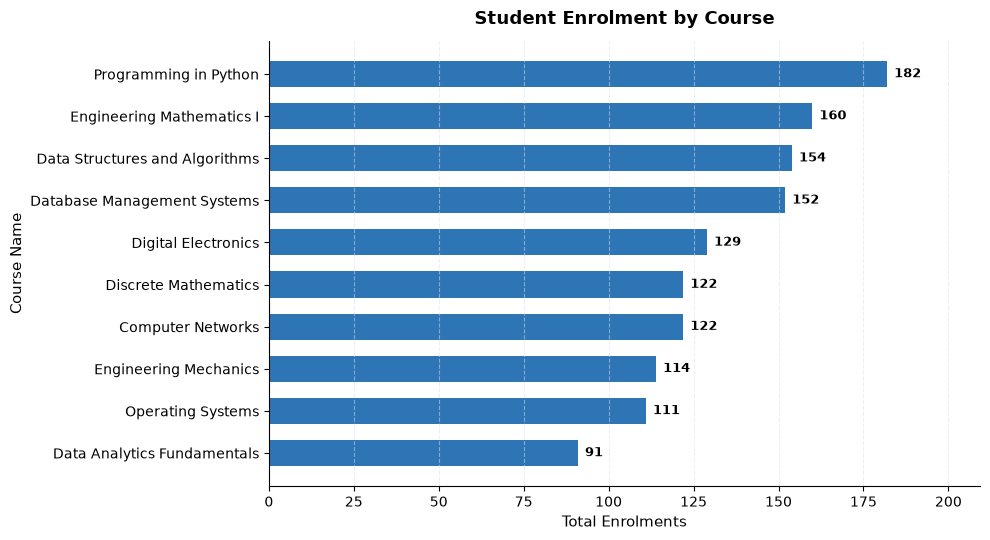

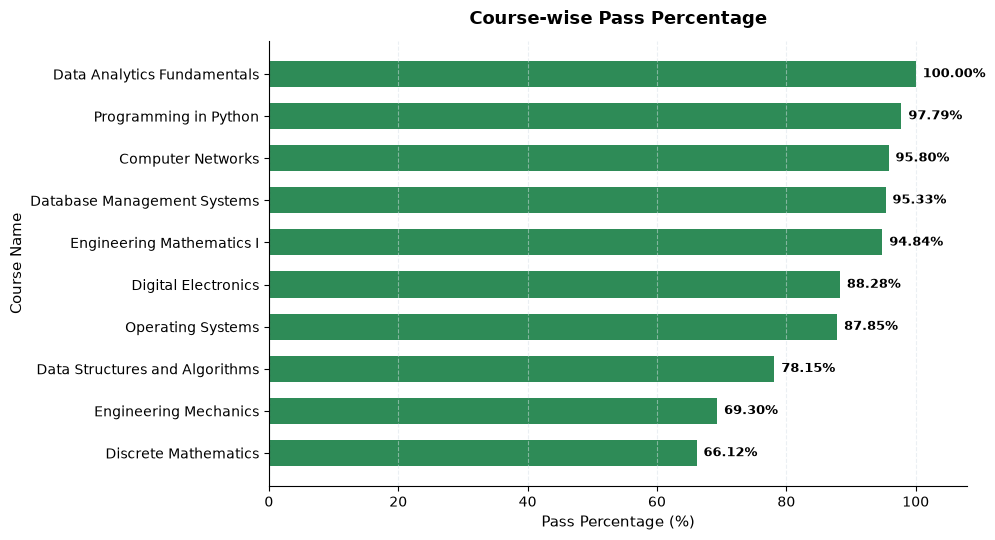

In [5]:
display(course_df)

# Chart A: Student Enrolment by Course
plot_enrol = course_df.sort_values(by="enrolment_count", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(plot_enrol["course_name"], plot_enrol["enrolment_count"], color=CHART_PALETTE["secondary"], height=0.62)
for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{int(w)}", xy=(w, bar.get_y() + bar.get_height() / 2), xytext=(5, 0),
                textcoords="offset points", va="center", ha="left", fontsize=9, fontweight="bold")
ax.set_title("Student Enrolment by Course", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Total Enrolments", fontsize=10.5)
ax.set_ylabel("Course Name", fontsize=10.5)
ax.set_xlim(0, plot_enrol["enrolment_count"].max() * 1.15)
ax.grid(axis="x", linestyle="--", alpha=0.5, color=CHART_PALETTE["grid"])
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

# Chart B: Course-wise Pass Percentage (no 40% pass-rate reference line)
plot_pass = course_df.dropna(subset=["pass_rate"]).sort_values(by="pass_rate", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(plot_pass["course_name"], plot_pass["pass_rate"].astype(float), color=CHART_PALETTE["pass"], height=0.62)
for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{w:.2f}%", xy=(w, bar.get_y() + bar.get_height() / 2), xytext=(5, 0),
                textcoords="offset points", va="center", ha="left", fontsize=9, fontweight="bold")
ax.set_title("Course-wise Pass Percentage", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Pass Percentage (%)", fontsize=10.5)
ax.set_ylabel("Course Name", fontsize=10.5)
ax.set_xlim(0, 108)
ax.grid(axis="x", linestyle="--", alpha=0.5, color=CHART_PALETTE["grid"])
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

### Observations — Course-wise Analysis
- **Highest Enrolment:** `BT102` (*Programming in Python*) leads with **182** enrolments, followed by `BT101` (*Engineering Mathematics I*, **160**), `BT103` (*Data Structures and Algorithms*, **154**), and `BT105` (*Database Management Systems*, **152**). `BT110` (*Data Analytics Fundamentals*) has the lowest enrolment (**91**).
- **Highest & Lowest Pass Rates:** `BT110` achieved a **100.00%** pass rate (`91/91`, avg marks `77.46`), followed by `BT102` (**97.79%**). At the lower end, `BT108` (*Discrete Mathematics*) recorded **66.12%** and `BT106` (*Engineering Mechanics*) recorded **69.30%**.
- **Courses Requiring Academic Improvement:** `BT108` (**41** failures, **33.88%** fail rate), `BT106` (**35** failures, **30.70%** fail rate), and `BT103` (**33** failures, **21.85%** fail rate) account for `109` of the `161` total failures (`67.70%` of all failures).

## 6. Semester-wise Academic Performance Analysis

Here we examine how enrolment volume, pass percentage, and average marks change across Semesters `1` through `4`.

,semester,enrolment_count,valid_enrolments,pass_count,fail_count,average_marks,pass_rate,fail_rate
0,1,413,406,355,51,61.04,87.44,12.56
1,2,407,401,355,46,61.21,88.53,11.47
2,3,256,254,219,35,59.07,86.22,13.78
3,4,261,256,227,29,62.23,88.67,11.33


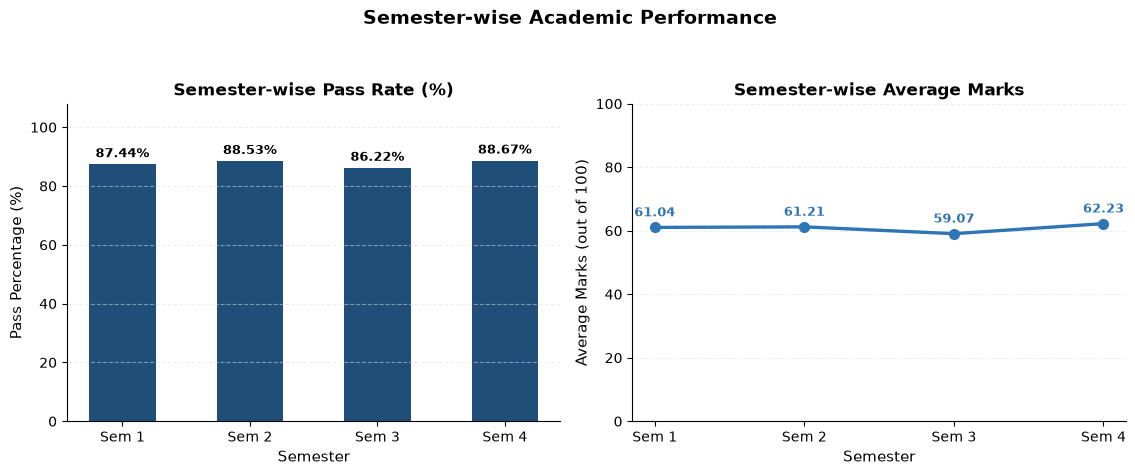

In [6]:
display(semester_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.8))
sem_labels = [f"Sem {int(s)}" for s in semester_df["semester"]]

bars = ax1.bar(sem_labels, semester_df["pass_rate"].astype(float), color=CHART_PALETTE["primary"], width=0.52)
for bar in bars:
    h = bar.get_height()
    ax1.annotate(f"{h:.2f}%", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 5),
                 textcoords="offset points", ha="center", fontsize=9, fontweight="bold")
ax1.set_title("Semester-wise Pass Rate (%)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Semester", fontsize=10.5)
ax1.set_ylabel("Pass Percentage (%)", fontsize=10.5)
ax1.set_ylim(0, 108)
ax1.grid(axis="y", linestyle="--", alpha=0.5, color=CHART_PALETTE["grid"])
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

avg_vals = semester_df["average_marks"].astype(float)
ax2.plot(sem_labels, avg_vals, marker="o", linewidth=2.4, markersize=7, color=CHART_PALETTE["secondary"])
for idx, val in enumerate(avg_vals):
    ax2.annotate(f"{val:.2f}", (idx, val), textcoords="offset points", xytext=(0, 8),
                 ha="center", fontsize=9, fontweight="bold", color=CHART_PALETTE["secondary"])
ax2.set_title("Semester-wise Average Marks", fontsize=12, fontweight="bold")
ax2.set_xlabel("Semester", fontsize=10.5)
ax2.set_ylabel("Average Marks (out of 100)", fontsize=10.5)
ax2.set_ylim(0, 100)
ax2.grid(axis="y", linestyle="--", alpha=0.5, color=CHART_PALETTE["grid"])
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

fig.suptitle("Semester-wise Academic Performance", fontsize=13.5, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### Observations — Semester-wise Analysis
- **Enrolment Volume:** Semesters `1` (**413** enrolments) and `2` (**407** enrolments) have higher enrolment counts than Semesters `3` (**256**) and `4` (**261**) because both the `2023` and `2024` admission cohorts have completed Semesters `1–2`, whereas only the `2023` cohort has progressed to Semesters `3–4`.
- **Performance Trend:** Pass percentages remain steady between **86.22%** (Semester `3`, avg marks **59.07**) and **88.67%** (Semester `4`, avg marks **62.23**), showing a mild dip in Semester `3` followed by recovery in Semester `4`.

## 7. Department-wise Enrolment & Performance Analysis

We compare unique students, total enrolment volume, average marks, and pass rates across the five B.Tech departments (`CSE`, `IT`, `ECE`, `ME`, `CE`) using two separate charts: **Department-wise Enrolment Count** and **Department-wise Pass Percentage**.

,department,unique_students,enrolment_count,valid_enrolments,pass_count,fail_count,average_marks,pass_rate,fail_rate
0,CSE,86,468,460,404,56,61.33,87.83,12.17
1,IT,46,271,267,233,34,59.92,87.27,12.73
2,ME,49,243,240,207,33,60.82,86.25,13.75
3,ECE,42,220,217,189,28,61.00,87.10,12.90
4,CE,27,135,133,123,10,61.77,92.48,7.52


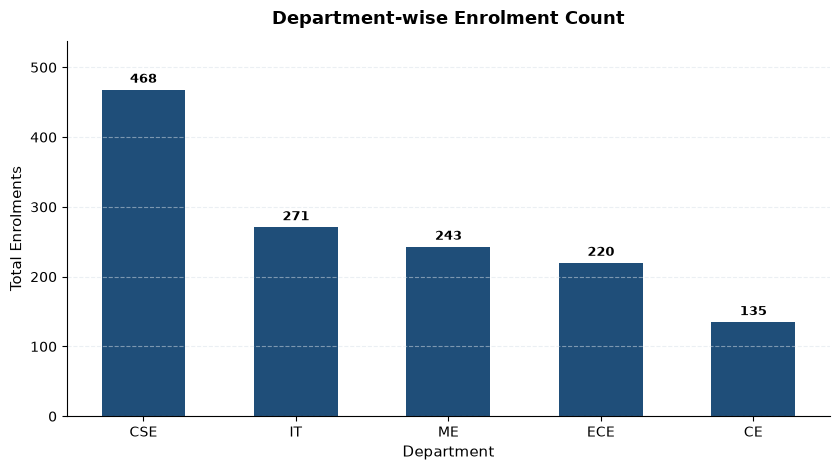

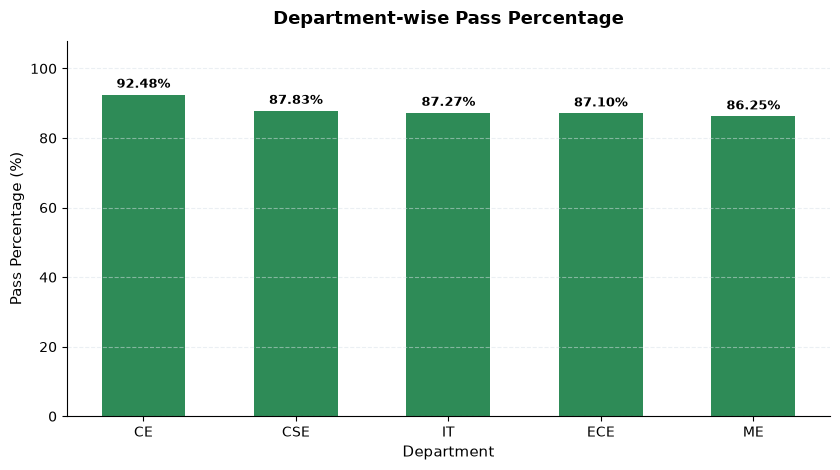

In [7]:
display(department_df)

# Chart 1: Department-wise Enrolment Count
fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.bar(department_df["department"], department_df["enrolment_count"], color=CHART_PALETTE["primary"], width=0.55)
for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{int(h)}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 5),
                textcoords="offset points", ha="center", fontsize=9.5, fontweight="bold")
ax.set_title("Department-wise Enrolment Count", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Department", fontsize=10.5)
ax.set_ylabel("Total Enrolments", fontsize=10.5)
ax.set_ylim(0, department_df["enrolment_count"].max() * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.5, color=CHART_PALETTE["grid"])
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

# Chart 2: Department-wise Pass Percentage
dept_pass_df = department_df.dropna(subset=["pass_rate"]).sort_values(by="pass_rate", ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.bar(dept_pass_df["department"], dept_pass_df["pass_rate"].astype(float), color=CHART_PALETTE["pass"], width=0.55)
for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{h:.2f}%", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 5),
                textcoords="offset points", ha="center", fontsize=9.5, fontweight="bold")
ax.set_title("Department-wise Pass Percentage", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Department", fontsize=10.5)
ax.set_ylabel("Pass Percentage (%)", fontsize=10.5)
ax.set_ylim(0, 108)
ax.grid(axis="y", linestyle="--", alpha=0.5, color=CHART_PALETTE["grid"])
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

### Observations — Department-wise Analysis
- **Enrolment Volume:** `CSE` is the largest department with **86** unique students and **468** enrolments (`35.00%` of all enrolments), followed by `IT` (**271**), `ME` (**243**), `ECE` (**220**), and `CE` (**135**).
- **Pass Percentage:** `CE` achieved the highest pass rate at **92.48%** (avg marks **61.77**), followed by `CSE` (**87.83%**), `IT` (**87.27%**), `ECE` (**87.10%**), and `ME` (**86.25%**).

## 8. Monthly Enrolment Trend Analysis

Using valid ISO `enrolment_date` values (`1,334` records after excluding the `3` invalid null dates logged in Phase 6), we group enrolments by month (`YYYY-MM`) to observe actual enrolment volume over time.

,year_month,enrolment_count
0,2023-08,204
1,2023-09,55
2,2024-01,156
3,2024-02,102
4,2024-08,317
5,2024-09,92
6,2025-01,274
7,2025-02,134


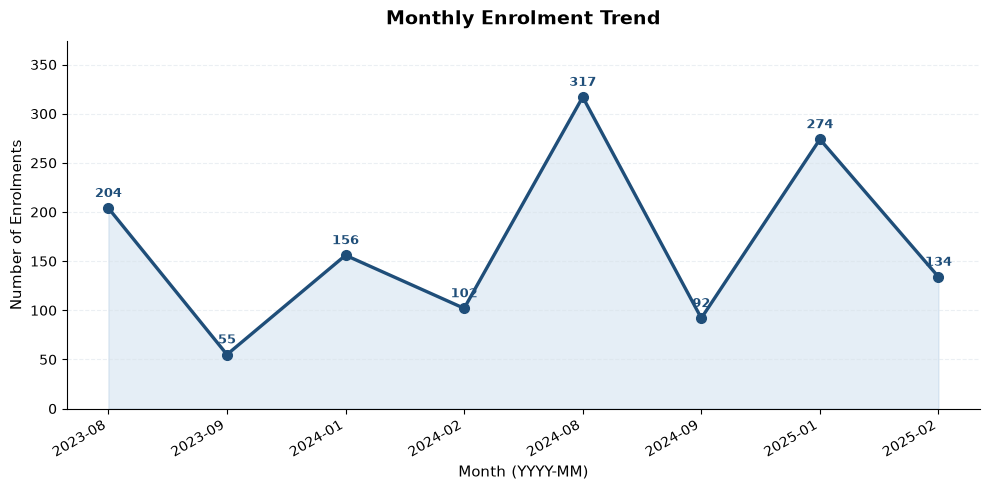

In [8]:
display(monthly_df)

fig, ax = plt.subplots(figsize=(10, 5))
x = monthly_df["year_month"]
y = monthly_df["enrolment_count"]
ax.plot(x, y, marker="o", linewidth=2.4, markersize=7, color=CHART_PALETTE["primary"])
ax.fill_between(range(len(x)), y, alpha=0.12, color=CHART_PALETTE["secondary"])
for idx, val in enumerate(y):
    ax.annotate(f"{int(val)}", (idx, val), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9, fontweight="bold", color=CHART_PALETTE["primary"])
ax.set_title("Monthly Enrolment Trend", fontsize=13.5, fontweight="bold", pad=12)
ax.set_xlabel("Month (YYYY-MM)", fontsize=10.5)
ax.set_ylabel("Number of Enrolments", fontsize=10.5)
ax.set_ylim(0, max(y) * 1.18)
ax.grid(axis="y", linestyle="--", alpha=0.5, color=CHART_PALETTE["grid"])
plt.xticks(rotation=30, ha="right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

### Observations — Monthly Enrolment Trend
- Enrolments occurred in **8 active months** across `2023-08` to `2025-02` (`1,334` dated records; `3` null dates excluded).
- Based on the calculated counts, the highest monthly enrolment occurred in **`2024-08` (317)**, followed by **`2025-01` (274)**, **`2023-08` (204)**, and **`2024-01` (156)**, while **`2023-09` (55)** and **`2024-09` (92)** recorded lower tail-end registrations.

## 9. Attendance vs. Marks Correlation Analysis

We filter to records where both `attendance_percentage` and `marks` are non-null, compute summary statistics using NumPy and Pandas, calculate the Pearson correlation coefficient `r`, and plot a scatter chart coloured by `Pass` vs. `Fail`. Importantly, **correlation measures linear association only and does not imply causation**.

Paired non-null records          : 1307
Attendance mean / std (NumPy)    : 77.83% / 10.52%
Marks mean / std (NumPy)         : 60.92 / 18.28
Average Attendance (Pass)        : 79.73%
Average Attendance (Fail)        : 64.32%
Pearson Correlation (r)          : 0.7539


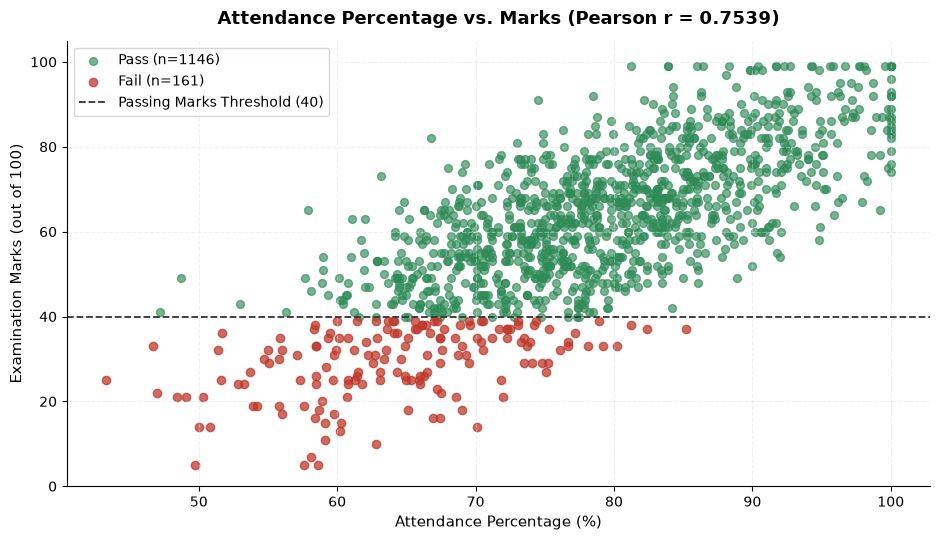

In [9]:
att_marks_df = merged_df[["attendance_percentage", "marks", "result"]].dropna(
    subset=["attendance_percentage", "marks"]
)
att_arr = att_marks_df["attendance_percentage"].astype(float).to_numpy()
marks_arr = att_marks_df["marks"].astype(float).to_numpy()
pearson_r = float(np.corrcoef(att_arr, marks_arr)[0, 1])

print(f"Paired non-null records          : {len(att_marks_df)}")
print(f"Attendance mean / std (NumPy)    : {np.mean(att_arr):.2f}% / {np.std(att_arr):.2f}%")
print(f"Marks mean / std (NumPy)         : {np.mean(marks_arr):.2f} / {np.std(marks_arr):.2f}")
print(f"Average Attendance (Pass)        : {kpis['attendance_vs_marks']['average_attendance_pass']}%")
print(f"Average Attendance (Fail)        : {kpis['attendance_vs_marks']['average_attendance_fail']}%")
print(f"Pearson Correlation (r)          : {pearson_r:.4f}")

pass_pts = att_marks_df[att_marks_df["result"] == "Pass"]
fail_pts = att_marks_df[att_marks_df["result"] == "Fail"]

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.scatter(
    pass_pts["attendance_percentage"].astype(float),
    pass_pts["marks"].astype(float),
    alpha=0.65,
    s=32,
    color=CHART_PALETTE["pass"],
    label=f"Pass (n={len(pass_pts)})",
)
ax.scatter(
    fail_pts["attendance_percentage"].astype(float),
    fail_pts["marks"].astype(float),
    alpha=0.75,
    s=36,
    color=CHART_PALETTE["fail"],
    label=f"Fail (n={len(fail_pts)})",
)
ax.axhline(
    PASSING_MARKS,
    color="#333333",
    linestyle="--",
    linewidth=1.3,
    label=f"Passing Marks Threshold ({PASSING_MARKS})",
)

ax.set_title(f"Attendance Percentage vs. Marks (Pearson r = {pearson_r:.4f})", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Attendance Percentage (%)", fontsize=10.5)
ax.set_ylabel("Examination Marks (out of 100)", fontsize=10.5)
ax.set_ylim(0, 105)
ax.grid(True, linestyle="--", alpha=0.45, color=CHART_PALETTE["grid"])
ax.legend(loc="upper left", frameon=True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

### Observations — Attendance vs. Marks Correlation
- Across **1,307** paired non-null records, attendance percentage and marks show a strong positive Pearson correlation of **`r = 0.7539`**.
- Passed enrolments averaged **79.73%** attendance compared to **64.32%** for failed enrolments.
- **Important Statistical Note:** Correlation does **not** imply causation. Higher attendance alone does not automatically guarantee higher marks; underlying factors such as student motivation, consistent study habits, prior subject preparation, and course difficulty can influence both class attendance and examination scores.

## 10. Key Insights, Recommendations & Conclusion

### Answers to the Five Business Questions
1. **Highest Student Enrolment:** `BT102` *Programming in Python* (**182** enrolments), followed by `BT101` *Engineering Mathematics I* (**160**) and `BT103` *Data Structures and Algorithms* (**154**).
2. **Highest & Lowest Pass Rates:** Highest is `BT110` *Data Analytics Fundamentals* (**100.00%**); lowest is `BT108` *Discrete Mathematics* (**66.12%**), followed by `BT106` *Engineering Mechanics* (**69.30%**).
3. **Overall Student Pass Percentage:** **87.78%** (`1,156` passed out of `1,317` valid graded enrolments).
4. **Performance Across Semesters:** Pass rates stay consistent between **86.22%** (Sem `3`, avg marks **59.07**) and **88.67%** (Sem `4`, avg marks **62.23**), with Semesters `1` (**87.44%**) and `2` (**88.53%**) carrying higher total enrolments.
5. **Courses Requiring Academic Improvement:** `BT108` (*Discrete Mathematics*, **41** failures / **33.88%** fail rate), `BT106` (*Engineering Mechanics*, **35** failures / **30.70%** fail rate), and `BT103` (*Data Structures and Algorithms*, **33** failures / **21.85%** fail rate).

### Actionable Recommendations
- Arrange remedial problem-solving tutorials and practice labs for **`BT108`**, **`BT106`**, and **`BT103`**, which together contribute over two-thirds of all academic failures.
- Track mid-semester attendance early and provide timely faculty mentoring and academic support for students with consistently low attendance.
- Standardise exam data entry templates to prevent the `20` `Missing/Invalid` mark records and `3` invalid enrolment dates encountered in raw spreadsheets.

### Conclusion
By combining reproducible data cleaning (`data_cleaning.py`), verified KPI computation (`analysis.py`), and transparent exploratory analysis in this notebook, all totals reconcile across `reports/kpis.json` and the cleaned datasets, establishing a verified foundation for the Power BI dashboard.